In [ ]:
!pip install einops

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 kB 784.5 kB/s eta 0:00:00


In [ ]:
!pip install torchinfo

In [ ]:
import torch
from torch import nn
from torch import nn, einsum
import torch.nn.functional as F
from torch import optim
from einops import rearrange, repeat
from einops.layers.torch import Rearrange
import numpy as np
import torchvision
import time
from torchinfo import summary
import matplotlib.pyplot as plt
import time
import torch
import torch.nn.functional as F
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

In [ ]:
torch.manual_seed(42)

DOWNLOAD_PATH = '/data/mnist'
BATCH_SIZE_TRAIN = 100
BATCH_SIZE_TEST = 1000

transform_mnist = torchvision.transforms.Compose([torchvision.transforms.ToTensor(),torchvision.transforms.Normalize((0.1307,), (0.3081,))])

train_set = torchvision.datasets.MNIST(DOWNLOAD_PATH, train=True, download=True,transform=transform_mnist)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=BATCH_SIZE_TRAIN, shuffle=True)

test_set = torchvision.datasets.MNIST(DOWNLOAD_PATH, train=False, download=True,transform=transform_mnist)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=BATCH_SIZE_TEST, shuffle=True)

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 9912422/9912422 [00:00<00:00, 34709481.60it/s]


Extracting /data/mnist/MNIST/raw/train-images-idx3-ubyte.gz to /data/mnist/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 28881/28881 [00:00<00:00, 1125869.66it/s]


Extracting /data/mnist/MNIST/raw/train-labels-idx1-ubyte.gz to /data/mnist/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 1648877/1648877 [00:00<00:00, 9310682.81it/s]


Extracting /data/mnist/MNIST/raw/t10k-images-idx3-ubyte.gz to /data/mnist/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 4542/4542 [00:00<00:00, 1808308.38it/s]

Extracting /data/mnist/MNIST/raw/t10k-labels-idx1-ubyte.gz to /data/mnist/MNIST/raw



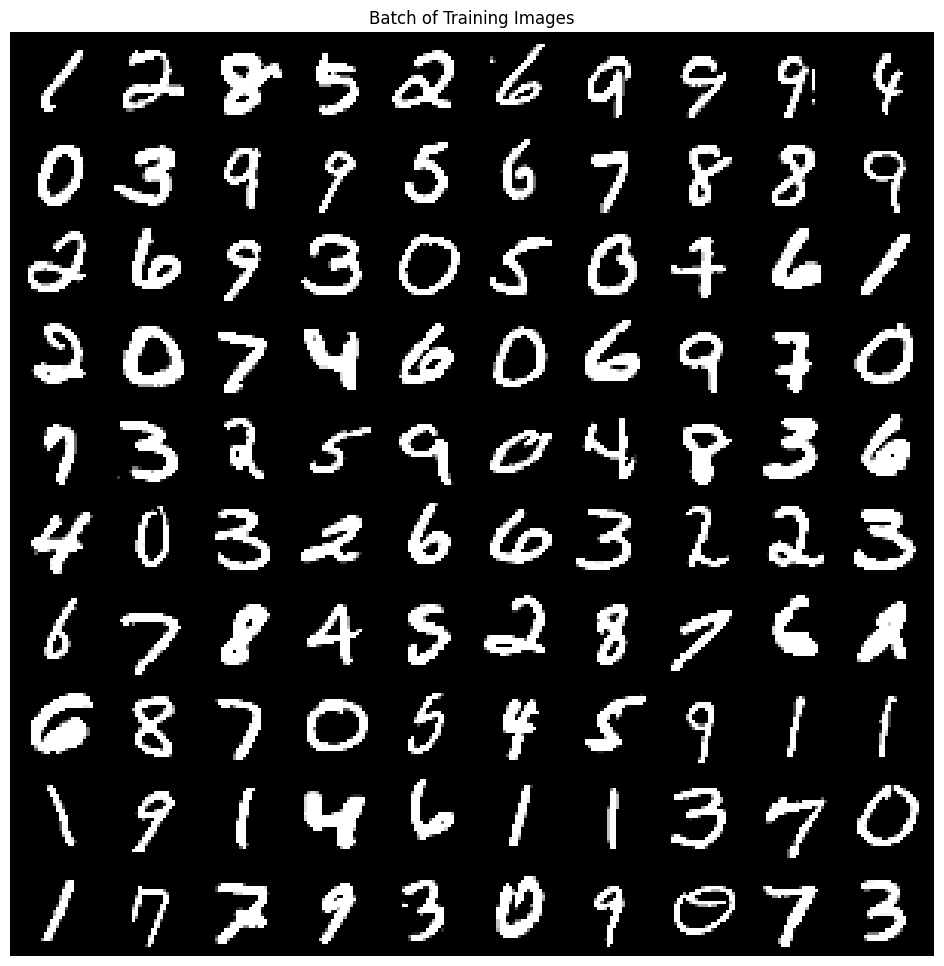

In [ ]:
# Function to show a batch of images
def show_batch(data_loader):
    batch = next(iter(data_loader))
    images, labels = batch
    grid = torchvision.utils.make_grid(images, nrow=10)
    plt.figure(figsize=(12, 12))
    plt.imshow(grid.numpy().transpose((1, 2, 0)))
    plt.title("Batch of Training Images")
    plt.axis('off')
    plt.show()

# Print images for validation
show_batch(train_loader)

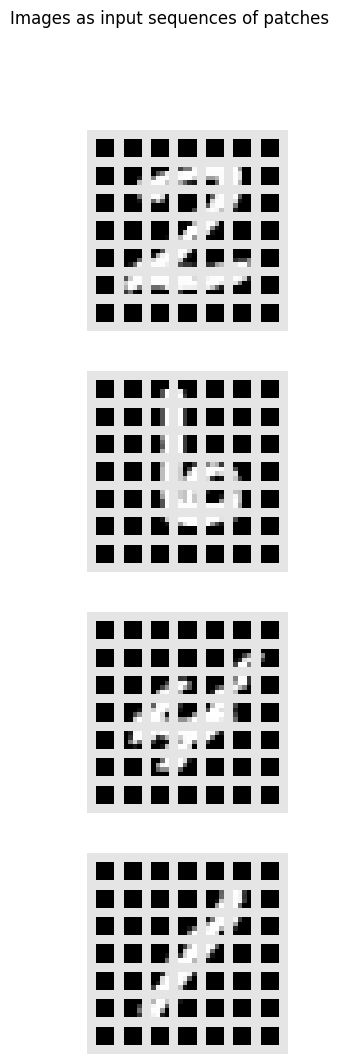

In [ ]:
image_size = 28
num_patches=49

# download MNIST training set and reserve 50000 for training
train_dataset = torchvision.datasets.MNIST(root='/data/torchvision/MNIST/training', train=True, download=True, transform=MNIST_preprocess)
train_set, val_set = torch.utils.data.random_split(train_dataset, [50000, 10000])

# download MNIST test set
test_set = torchvision.datasets.MNIST(root='/data/torchvision/MNIST/testing', train=False, download=True, transform=MNIST_preprocess)

# We define the data loaders using the datasets
train_loader = torch.utils.data.DataLoader(dataset=train_set, batch_size=32, shuffle=True)
val_loader = torch.utils.data.DataLoader(dataset=val_set, batch_size=32, shuffle=False)
test_loader = torch.utils.data.DataLoader(dataset=test_set, batch_size=32, shuffle=False)

def img_to_patch(x, patch_size, flatten_channels=True):
    """
    Inputs:
        x - Tensor representing the image of shape [B, C, H, W]
        patch_size - Number of pixels per dimension of the patches (integer)
        flatten_channels - If True, the patches will be returned in a flattened format
                           as a feature vector instead of a image grid.
    """
    B, C, H, W = x.shape # [B, C, H, W], MNIST [B, 1, 28, 28]
    x = x.reshape(B, C, H // patch_size, patch_size, W // patch_size, patch_size) # [B, C, H', p_H, W', p_W], MNIST [B, 1, 4, 7, 4, 7]
    x = x.permute(0, 2, 4, 1, 3, 5)  # [B, H', W', C, p_H, p_W], MNIST [B, 4, 4, 1, 7, 7]
    x = x.flatten(1, 2)  # [B, H'*W', C, p_H, p_W], MNIST [B, 16, 1, 7, 7]
    if flatten_channels:
        x = x.flatten(2, 4)  # [B, H'*W', C*p_H*p_W], MNIST [B, 16, 49]
    return x
# Visualize the image patches
img_patches = img_to_patch(MNIST_examples, patch_size=patch_size, flatten_channels=False)

fig, ax = plt.subplots(MNIST_examples.shape[0], 1, figsize=(14, 12))
fig.suptitle("Images as input sequences of patches")
for i in range(MNIST_examples.shape[0]):
    img_grid = torchvision.utils.make_grid(img_patches[i], nrow=int(image_size/patch_size), normalize=True, pad_value=0.9)
    img_grid = img_grid.permute(1, 2, 0)
    ax[i].imshow(img_grid)
    ax[i].axis("off")
plt.show()
plt.close()

In [ ]:
def pair(t):
    return t if isinstance(t, tuple) else (t, t)

# classes

class PreNorm(nn.Module):
    def __init__(self, dim, fn):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fn = fn
    def forward(self, x, **kwargs):
        return self.fn(self.norm(x), **kwargs)

class FeedForward(nn.Module):
    def __init__(self, dim, hidden_dim, dropout = 0.):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, dim),
            nn.Dropout(dropout)
        )
    def forward(self, x):
        return self.net(x)

class Attention(nn.Module):
    def __init__(self, dim, heads = 4, dim_head = 64, dropout = 0.):
        super().__init__()
        inner_dim = dim_head *  heads
        project_out = not (heads == 1 and dim_head == dim)

        self.heads = heads
        self.scale = dim_head ** -0.5

        self.attend = nn.Softmax(dim = -1)
        self.to_qkv = nn.Linear(dim, inner_dim * 3, bias = False)

        self.to_out = nn.Sequential(
            nn.Linear(inner_dim, dim),
            nn.Dropout(dropout)
        ) if project_out else nn.Identity()

    def forward(self, x):
        b, n, _, h = *x.shape, self.heads
        qkv = self.to_qkv(x).chunk(3, dim = -1)
        q, k, v = map(lambda t: rearrange(t, 'b n (h d) -> b h n d', h = h), qkv)

        dots = einsum('b h i d, b h j d -> b h i j', q, k) * self.scale

        attn = self.attend(dots)

        out = einsum('b h i j, b h j d -> b h i d', attn, v)
        out = rearrange(out, 'b h n d -> b n (h d)')
        return self.to_out(out)

class Transformer(nn.Module):
    def __init__(self, dim, depth, heads, dim_head, mlp_dim, dropout = 0.):
        super().__init__()
        self.layers = nn.ModuleList([])
        for _ in range(depth):
            self.layers.append(nn.ModuleList([
                PreNorm(dim, Attention(dim, heads = heads, dim_head = dim_head, dropout = dropout)),
                PreNorm(dim, FeedForward(dim, mlp_dim, dropout = dropout))
            ]))
    def forward(self, x):
        for attn, ff in self.layers:
            x = attn(x) + x
            x = ff(x) + x
        return x

class ViT(nn.Module):
    def __init__(self, *, image_size, patch_size, num_classes, dim, depth, heads, mlp_dim, pool = 'cls', channels = 3, dim_head = 64, dropout = 0., emb_dropout = 0.):
        super().__init__()
        image_height, image_width = pair(image_size)
        patch_height, patch_width = pair(patch_size)

        assert image_height % patch_height == 0 and image_width % patch_width == 0, 'Image dimensions must be divisible by the patch size.'

        num_patches = (image_height // patch_height) * (image_width // patch_width)
        patch_dim = channels * patch_height * patch_width
        assert pool in {'cls', 'mean'}, 'pool type must be either cls (cls token) or mean (mean pooling)'

        self.to_patch_embedding = nn.Sequential(
            Rearrange('b c (h p1) (w p2) -> b (h w) (p1 p2 c)', p1 = patch_height, p2 = patch_width),
            nn.Linear(patch_dim, dim),
        )

        self.pos_embedding = nn.Parameter(torch.randn(1, num_patches + 1, dim))
        self.cls_token = nn.Parameter(torch.randn(1, 1, dim))
        self.dropout = nn.Dropout(emb_dropout)

        self.transformer = Transformer(dim, depth, heads, dim_head, mlp_dim, dropout)

        self.pool = pool
        self.to_latent = nn.Identity()

        self.mlp_head = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, num_classes)
        )

    def forward(self, img):
        x = self.to_patch_embedding(img)
        b, n, _ = x.shape

        cls_tokens = repeat(self.cls_token, '() n d -> b n d', b = b)
        x = torch.cat((cls_tokens, x), dim=1)
        x += self.pos_embedding[:, :(n + 1)]
        x = self.dropout(x)

        x = self.transformer(x)

        x = x.mean(dim = 1) if self.pool == 'mean' else x[:, 0]

        x = self.to_latent(x)
        return self.mlp_head(x)


In [ ]:
model = ViT(image_size=28, patch_size=4, num_classes=10, channels=1, dim=64, depth=6, heads=4, mlp_dim=128)
optimizer = optim.Adam(model.parameters(), lr=0.003)

In [ ]:
summary(model)

Layer (type:depth-idx)                             Param #
ViT                                                3,264
├─Sequential: 1-1                                  --
│    └─Rearrange: 2-1                              --
│    └─Linear: 2-2                                 1,088
├─Dropout: 1-2                                     --
├─Transformer: 1-3                                 --
│    └─ModuleList: 2-3                             --
│    │    └─ModuleList: 3-1                        82,432
│    │    └─ModuleList: 3-2                        82,432
│    │    └─ModuleList: 3-3                        82,432
│    │    └─ModuleList: 3-4                        82,432
│    │    └─ModuleList: 3-5                        82,432
│    │    └─ModuleList: 3-6                        82,432
├─Identity: 1-4                                    --
├─Sequential: 1-5                                  --
│    └─LayerNorm: 2-4                              128
│    └─Linear: 2-5                            

In [ ]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(count_parameters(model))

499722


In [ ]:
def train_epoch(model, optimizer, data_loader, loss_history):
    total_samples = len(data_loader.dataset)
    model.train()

    for i, (data, target) in enumerate(data_loader):
        optimizer.zero_grad()
        output = F.log_softmax(model(data), dim=1)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()

        if i % 100 == 0:
            print('[' +  '{:5}'.format(i * len(data)) + '/' + '{:5}'.format(total_samples) +
                  ' (' + '{:3.0f}'.format(100 * i / len(data_loader)) + '%)]  Loss: ' +
                  '{:6.4f}'.format(loss.item()))
            loss_history.append(loss.item())

In [ ]:
def evaluate(model, data_loader, loss_history):
    model.eval()

    total_samples = len(data_loader.dataset)
    correct_samples = 0
    total_loss = 0

    with torch.no_grad():
        for data, target in data_loader:
            output = F.log_softmax(model(data), dim=1)
            loss = F.nll_loss(output, target, reduction='sum')
            _, pred = torch.max(output, dim=1)

            total_loss += loss.item()
            correct_samples += pred.eq(target).sum()

    avg_loss = total_loss / total_samples
    loss_history.append(avg_loss)
    print('\nAverage test loss: ' + '{:.4f}'.format(avg_loss) +
          '  Accuracy:' + '{:5}'.format(correct_samples) + '/' +
          '{:5}'.format(total_samples) + ' (' +
          '{:4.2f}'.format(100.0 * correct_samples / total_samples) + '%)\n')

In [ ]:
N_EPOCHS = 10
start_time = time.time()

train_loss_history, test_loss_history = [], []
train_accuracy_history, test_accuracy_history = [], []

def calculate_accuracy(output, target):
    _, pred = torch.max(output, dim=1)
    return pred.eq(target).sum().item() / len(target)

def train_epoch(model, optimizer, data_loader):
    model.train()
    total_samples = len(data_loader.dataset)
    total_loss = 0
    correct_samples = 0

    for i, (data, target) in enumerate(data_loader):
        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(F.log_softmax(output, dim=1), target)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(data)
        correct_samples += calculate_accuracy(output, target) * len(data)

        if i % 100 == 0:
            print(f'[{i * len(data)}/{total_samples} '
                  f'({100 * i / len(data_loader):.0f}%)]  '
                  f'Loss: {loss.item():.6f}')

    avg_loss = total_loss / total_samples
    avg_accuracy = correct_samples / total_samples
    return avg_loss, avg_accuracy

def evaluate(model, data_loader):
    model.eval()
    total_samples = len(data_loader.dataset)
    total_loss = 0
    correct_samples = 0

    with torch.no_grad():
        for data, target in data_loader:
            output = model(data)
            loss = F.nll_loss(F.log_softmax(output, dim=1), target, reduction='sum')
            total_loss += loss.item()
            correct_samples += calculate_accuracy(output, target) * len(data)

    avg_loss = total_loss / total_samples
    avg_accuracy = correct_samples / total_samples
    return avg_loss, avg_accuracy

for epoch in range(1, N_EPOCHS + 1):
    print(f'Epoch: {epoch}')

    # Train
    train_loss, train_accuracy = train_epoch(model, optimizer, train_loader)
    train_loss_history.append(train_loss)
    train_accuracy_history.append(train_accuracy)
    print(f'Train set: Average loss: {train_loss:.4f}, '
          f'Accuracy: {train_accuracy:.4f}')

    # Evaluate
    test_loss, test_accuracy = evaluate(model, test_loader)
    test_loss_history.append(test_loss)
    test_accuracy_history.append(test_accuracy)
    print(f'Test set: Average loss: {test_loss:.4f}, '
          f'Accuracy: {test_accuracy:.4f}')

print(f'Execution time: {time.time() - start_time:.2f} seconds')

# Print final metrics
print("\nFinal Results:")
print(f"Train Loss: {train_loss_history[-1]:.4f}")
print(f"Train Accuracy: {train_accuracy_history[-1]:.4f}")
print(f"Test Loss: {test_loss_history[-1]:.4f}")
print(f"Test Accuracy: {test_accuracy_history[-1]:.4f}")

Epoch: 1
[0/60000 (0%)]  Loss: 2.406107
[10000/60000 (17%)]  Loss: 0.532789
[20000/60000 (33%)]  Loss: 0.326018
[30000/60000 (50%)]  Loss: 0.327928
[40000/60000 (67%)]  Loss: 0.299001
[50000/60000 (83%)]  Loss: 0.296495
Train set: Average loss: 0.4491, Accuracy: 0.8552
Test set: Average loss: 0.2694, Accuracy: 0.9121
Epoch: 2
[0/60000 (0%)]  Loss: 0.278969
[10000/60000 (17%)]  Loss: 0.088536
[20000/60000 (33%)]  Loss: 0.115874
[30000/60000 (50%)]  Loss: 0.140189
[40000/60000 (67%)]  Loss: 0.129145
[50000/60000 (83%)]  Loss: 0.290136
Train set: Average loss: 0.1789, Accuracy: 0.9446
Test set: Average loss: 0.1633, Accuracy: 0.9507
Epoch: 3
[0/60000 (0%)]  Loss: 0.049897
[10000/60000 (17%)]  Loss: 0.157736
[20000/60000 (33%)]  Loss: 0.166823
[30000/60000 (50%)]  Loss: 0.197319
[40000/60000 (67%)]  Loss: 0.213129
[50000/60000 (83%)]  Loss: 0.084280
Train set: Average loss: 0.1386, Accuracy: 0.9563
Test set: Average loss: 0.1253, Accuracy: 0.9629
Epoch: 4
[0/60000 (0%)]  Loss: 0.099079
[10

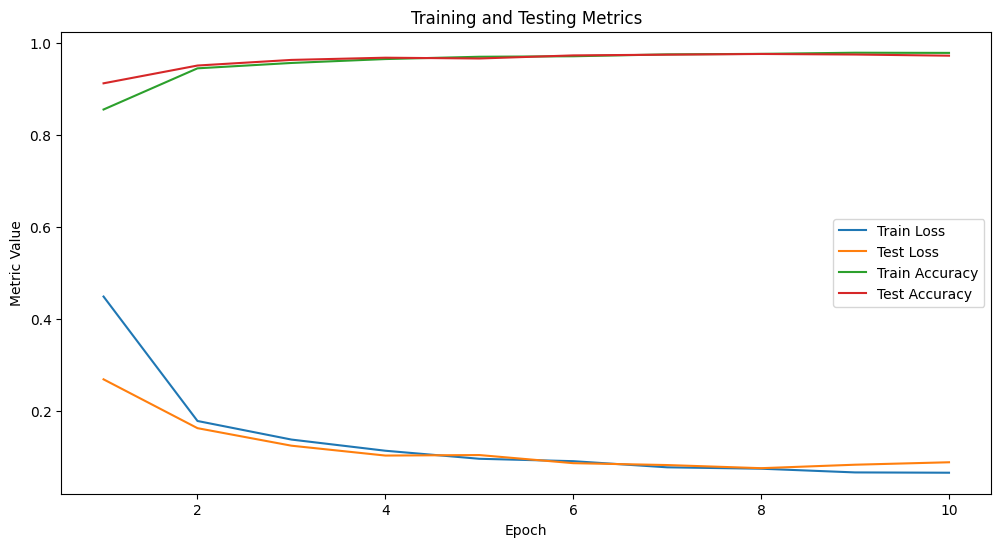

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(range(1, N_EPOCHS + 1), train_loss_history, label='Train Loss')
plt.plot(range(1, N_EPOCHS + 1), test_loss_history, label='Test Loss')
plt.plot(range(1, N_EPOCHS + 1), train_accuracy_history, label='Train Accuracy')
plt.plot(range(1, N_EPOCHS + 1), test_accuracy_history, label='Test Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Metric Value')
plt.title('Training and Testing Metrics')
plt.legend()
plt.show()

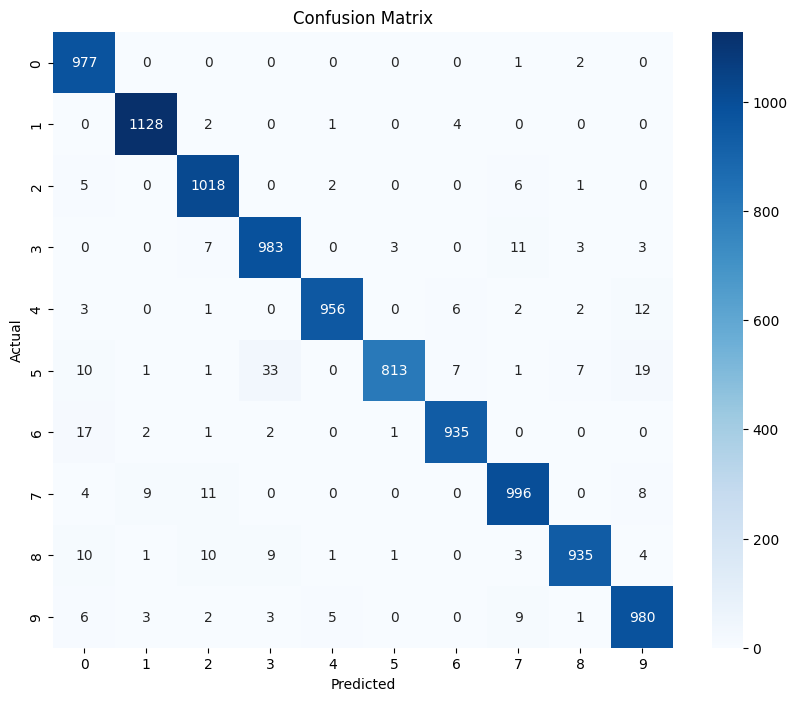

In [ ]:
# Confusion matrix
def plot_confusion_matrix(model, data_loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for data, target in data_loader:
            output = model(data)
            _, preds = torch.max(output, dim=1)
            all_preds.extend(preds.numpy())
            all_labels.extend(target.numpy())

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

plot_confusion_matrix(model, test_loader)

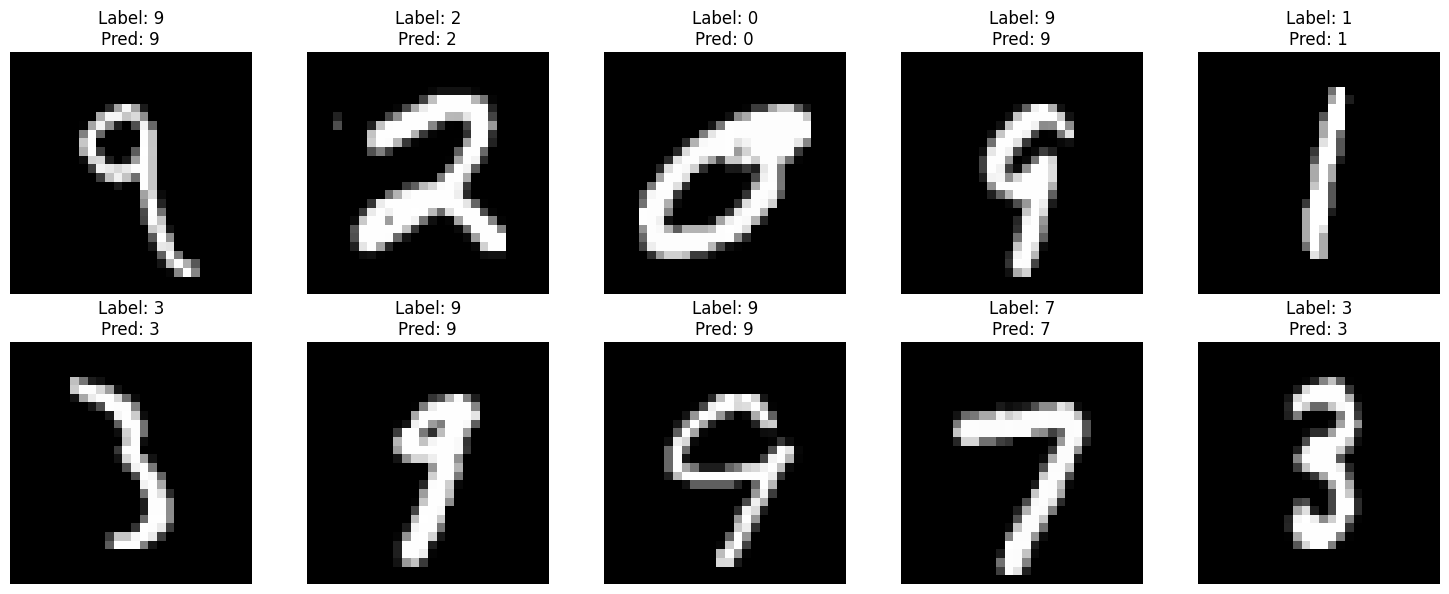

In [ ]:
# Visualize correct and wrong predictions
def plot_predictions(model, data_loader):
    model.eval()
    all_preds = []
    all_labels = []
    all_images = []

    with torch.no_grad():
        for data, target in data_loader:
            output = model(data)
            _, preds = torch.max(output, dim=1)
            all_preds.extend(preds.numpy())
            all_labels.extend(target.numpy())
            all_images.extend(data.numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_images = np.array(all_images)

    # Plot example images with predictions
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()
    for i, ax in enumerate(axes):
        ax.imshow(all_images[i][0], cmap='gray')
        ax.set_title(f'Label: {all_labels[i]}\nPred: {all_preds[i]}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

plot_predictions(model, test_loader)

In [ ]:
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, SubsetRandomSampler
from torchvision import datasets, transforms
from einops import rearrange, repeat
from einops.layers.torch import Rearrange
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import ParameterSampler
import time

In [ ]:
def create_dataloaders(batch_size, valid_size=0.1):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])

    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

    num_train = len(train_dataset)
    indices = list(range(num_train))
    split = int(np.floor(valid_size * num_train))
    np.random.shuffle(indices)

    train_idx, valid_idx = indices[split:], indices[:split]
    train_sampler = SubsetRandomSampler(train_idx)
    valid_sampler = SubsetRandomSampler(valid_idx)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, sampler=train_sampler)
    valid_loader = DataLoader(train_dataset, batch_size=batch_size, sampler=valid_sampler)
    test_loader = DataLoader(test_dataset, batch_size=batch_size)

    return train_loader, valid_loader, test_loader




def train(model, train_loader, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = F.cross_entropy(output, target)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        pred = output.argmax(dim=1, keepdim=True)
        correct += pred.eq(target.view_as(pred)).sum().item()
    return total_loss / len(train_loader), correct / len(train_loader.dataset)

def evaluate(model, data_loader, device):
    model.eval()
    total_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in data_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            total_loss += F.cross_entropy(output, target, reduction='sum').item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()
    return total_loss / len(data_loader.dataset), correct / len(data_loader.dataset)

In [ ]:
def hyperparameter_search(n_iter=10, n_epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Define the hyperparameter space
    param_distributions = {
        'dim': [32, 64, 128, 256],
        'depth': [2, 4, 6, 8],
        'heads': [2, 4, 8],
        'mlp_dim': [64, 128, 256, 512],
        'patch_size': [2, 4, 7],
        'learning_rate': [1e-4, 3e-4, 1e-3, 3e-3],
        'batch_size': [32, 64, 128]
    }

    # Generate random hyperparameter combinations
    param_list = list(ParameterSampler(param_distributions, n_iter=n_iter, random_state=42))

    best_accuracy = 0
    best_params = None
    results = []

    for i, params in enumerate(param_list):
        print(f"Trial {i+1}/{n_iter}")
        print(f"Parameters: {params}")

        # Create data loaders
        train_loader, valid_loader, test_loader = create_dataloaders(params['batch_size'])

        # Create model
        model = ViT(
            image_size=28,
            patch_size=params['patch_size'],
            num_classes=10,
            dim=params['dim'],
            depth=params['depth'],
            heads=params['heads'],
            mlp_dim=params['mlp_dim'],
            channels=1
        ).to(device)

        # Create optimizer
        optimizer = optim.Adam(model.parameters(), lr=params['learning_rate'])

        # Train and evaluate
        for epoch in range(n_epochs):
            train_loss, train_acc = train(model, train_loader, optimizer, device)
            valid_loss, valid_acc = evaluate(model, valid_loader, device)
            print(f"Epoch {epoch+1}/{n_epochs}: Train Acc: {train_acc:.4f}, Valid Acc: {valid_acc:.4f}")

        # Final evaluation on test set
        test_loss, test_acc = evaluate(model, test_loader, device)
        print(f"Test Accuracy: {test_acc:.4f}")

        results.append({**params, 'test_accuracy': test_acc})

        if test_acc > best_accuracy:
            best_accuracy = test_acc
            best_params = params

    print("\nBest Hyperparameters:")
    print(best_params)
    print(f"Best Test Accuracy: {best_accuracy:.4f}")

    # Plot results
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.scatter([r['dim'] for r in results], [r['test_accuracy'] for r in results])
    ax.set_xlabel('Dimension')
    ax.set_ylabel('Test Accuracy')
    ax.set_title('Hyperparameter Search Results')
    plt.show()

    return best_params, results

if __name__ == "__main__":
    start_time = time.time()
    best_params, results = hyperparameter_search(n_iter=10, n_epochs=10)
    end_time = time.time()
    print(f"Total execution time: {end_time - start_time:.2f} seconds")

Trial 1/10
Parameters: {'patch_size': 7, 'mlp_dim': 256, 'learning_rate': 0.003, 'heads': 8, 'dim': 64, 'depth': 4, 'batch_size': 32}
Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 9912422/9912422 [00:00<00:00, 13934219.29it/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 28881/28881 [00:00<00:00, 8217046.11it/s]

Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw



Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 1648877/1648877 [00:00<00:00, 12964679.12it/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 4542/4542 [00:00<00:00, 6268683.37it/s]


Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw

Epoch 1/10: Train Acc: 0.7980, Valid Acc: 0.0917
Epoch 2/10: Train Acc: 0.8387, Valid Acc: 0.0936
Epoch 3/10: Train Acc: 0.8426, Valid Acc: 0.0947
Epoch 4/10: Train Acc: 0.8555, Valid Acc: 0.0938
Epoch 5/10: Train Acc: 0.8605, Valid Acc: 0.0959
Epoch 6/10: Train Acc: 0.8654, Valid Acc: 0.0960
Epoch 7/10: Train Acc: 0.8699, Valid Acc: 0.0964
Epoch 8/10: Train Acc: 0.8717, Valid Acc: 0.0965
Epoch 9/10: Train Acc: 0.8751, Valid Acc: 0.0964
Epoch 10/10: Train Acc: 0.8766, Valid Acc: 0.0970
Test Accuracy: 0.9718
Trial 2/10
Parameters: {'patch_size': 7, 'mlp_dim': 64, 'learning_rate': 0.0003, 'heads': 4, 'dim': 64, 'depth': 4, 'batch_size': 128}
Epoch 1/10: Train Acc: 0.7495, Valid Acc: 0.0943
Epoch 2/10: Train Acc: 0.8608, Valid Acc: 0.0961
Epoch 3/10: Train Acc: 0.8716, Valid Acc: 0.0967
Epoch 4/10: Train Acc: 0.8777, Valid Acc: 0.0971
Epoch 5/10: Train Acc: 0.8813, Valid Acc: 0.0975
Epoch 6/10: Train Acc: 0.8851, V